# Voorspel herseninfarct

##### groepnaam: Groep 7 (RSR)



##### namen: Resham Anwar (25141511), Sharina Nasrullah (25103083), Rishano Narraina (25113011)
##### Kaggle usernames: Resham Anwar, SharinaHHS, 

## libraries importeren

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## datasets importeren

### train data

In [36]:
train= pd.read_csv('train.csv')
train

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,True,False,True,...,False,False,False,True,True,False,False,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,False,False,...,False,True,False,False,False,True,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,True,...,False,False,False,True,True,False,False,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,False,False,...,False,False,False,False,False,True,False,False,True,0


### test data

In [37]:
test= pd.read_csv('test.csv')
test

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,32840,52.0,0,0,97.32,21.8,True,False,False,False,...,False,False,True,False,False,False,True,False,False,True
1,45158,30.0,0,0,227.99,47.7,True,False,False,False,...,False,False,True,False,False,False,True,False,False,True
2,56105,26.0,0,0,113.28,24.4,True,False,False,False,...,False,False,True,False,False,False,True,False,True,False
3,3112,24.0,0,0,79.15,21.0,True,False,False,False,...,False,False,True,False,False,False,True,True,False,False
4,35224,63.0,0,0,89.69,33.3,True,False,False,False,...,False,False,True,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8383,60672,24.0,0,0,77.54,25.0,True,False,False,True,...,False,False,True,False,False,True,False,False,True,False
8384,25989,17.0,0,0,99.99,22.7,True,False,False,True,...,False,False,False,True,False,True,False,False,True,False
8385,34072,11.0,0,0,80.11,22.2,True,False,False,True,...,False,False,False,False,True,False,True,False,False,False
8386,32400,16.0,0,0,105.26,47.5,True,False,False,True,...,False,False,True,False,False,True,False,False,True,False


### sample data

In [38]:
sample= pd.read_csv('sample_submission.csv')
sample

,id,stroke
0,32840,1
1,45158,0
2,56105,1
3,3112,0
4,35224,1
...,...,...
8383,60672,0
8384,25989,0
8385,34072,1
8386,32400,0


## 1. Data begrijpen & Exploratieve Data Analyse 

### 1.1 beschrijving van de kolommen

| kolom | uileg | type |
|-------|-------|------|
| id    | unieke identificatie van de patiënt | numeriek |
| age   | leeftijd van de patiënt | numeriek |
| hypertension | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. 0 = nee, 1 = ja | numeriek (binair) |
| heart_disease | Geeft aan of de patiënt hartaandoening heeft: 0 = nee, 1 = ja | numeriek (binair) |
| avg_glucose_level| gemiddelde glucosegehalte van de patiënt | numeriek |
| bmi | Body Mass Index van de patiënt| numeriek |
| gender_Female | geeft aan of de patiënt een vrouw is. False = nee, True = ja | numeriek (binair) |
| gender_Male | geeft aan of de patiënt een man is. False = nee, True = ja | numeriek (binair) |
| gender_Other | geeft aan of de patiënt onder de categorie "other" valt. False = nee, True = ja | numeriek (binair) |
| ever_married_no | geeft aan of de patiënt nooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| ever_married_Yes | geeft aan of de patiënt ooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| work_type_Govt_job | geeft aan of de patiënt een overheidsbaan heeft. False = nee, True = ja | numeriek (binair) |
| work_type_Never_worked | geeft aan of de patiënt nooit heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Private | geeft aan of de patiënt in de private sector heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Self-employed | geeft aan of de patiënt zelfstandig ondernemer is. False = nee, True = ja | numeriek (binair) |
| work_type_children | geeft aan of de patiënt met kinderen werkt | numeriek (binair) |                                            
| Residence_type_Rural | geeft aan of de patiënt in een landelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| Residence_type_Urban | geeft aan of de patiënt in een stedelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| smoking_status_formerly smoked | geeft aan of de patiënt vroeger rookte. False = nee, True = ja | numeriek (binair) |
| smoking_status_never smoked | geeft aan dat de patiënt nooit heeft gerookt. False = nee, True = ja | numeriek (binair) |
| smoking_status_smokes | geeft aan dat de patiënt rookt. False = nee, True = ja | numeriek (binair) |
| stroke | doelvariabele. geeft aan of de patiënt een stroke heeft gehad | numeriek (binair) |

### 1.2 Data exploren

#### hoever voldoet de data aan de minimale vereisten van ML

##### de dataset voldoet grotendeels aan de minimale vereisten om gebruik te kunnen worden voor Machine Learning met Scikit-learn. de dataset bevat voldoende observaties en de variabelen zijn numeriek. de categorische variabelen zijn al omgezet naar dummy-variabelen, waardoor deze direct door de meeste Scikit-learn-modellen kunnen worden gebruikt.

##### de kolom 'stroke' wordt als target variabele gebruikt. ook is het kolom 'id' verwijderd uit de kolommen omdat, het geen voorspellende waarde is.

##### tijdens de data-analyse is ook gekeken naar multicollineariteit tussen de onafhankelijke variabelen. hierbij bleek dat bij veel van de dummyvariabelen er een sterke samenhang lag. Om te voorkomen dat dit de Machine Learning-modellen negatief beïnvloedt, zijn de kolommen 'gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_never smoked' verwijderd.

##### daarnaast wordt de dataset gecontroleerd op ontbrekende waarden en dubbele rijen. eventuele ontbrekende of problematische waarden worden aangepast voordat de modellen worden getraind.

##### na deze controles, het verwijderen van id en het verwijderen van de variabelen met sterke multicollineariteit is de dataset geschikt om te gebruiken voor de verdere Machine Learning-analyse.

In [39]:
display(train.describe(include= "all"))
train.info()
display(train.dtypes)
display(train.isna().sum())
display(np.min(train['age']))
display(np.max(train['age']))
train.duplicated().sum()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550,33550,33550,33550,...,33550,33550,33550,33550,33550,33550,33550,33550,33550,33550.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2,...,2,2,2,2,2,2,2,2,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,True,False,False,False,...,False,True,False,False,False,True,False,False,False,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,20032,20038,33544,21426,...,33409,19279,28424,28702,16776,16776,27889,20948,28583,NaN
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

id                                0
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
gender_Female                     0
gender_Male                       0
gender_Other                      0
ever_married_No                   0
ever_married_Yes                  0
work_type_Govt_job                0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Rural              0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
stroke                            0
dtype: int64

np.float64(0.08)

np.float64(82.0)

np.int64(0)

### 1.3 Data splitsing en controle

In [40]:
X= train.drop(columns= ['stroke', 'id'])
y= train['stroke']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (33550, 20)
y shape: (33550,)


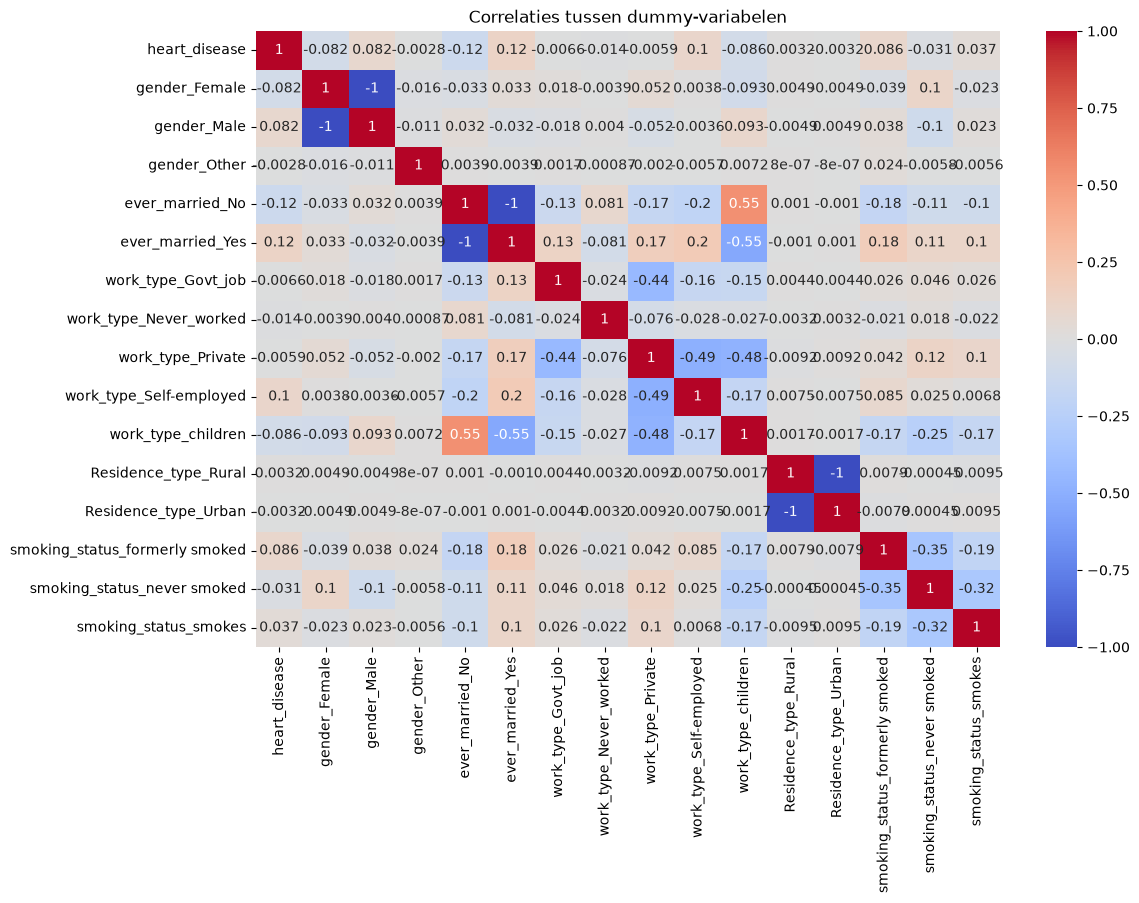

In [41]:
dummy_cols = [
    col for col in train.columns 
    if "_" in col and col not in ["avg_glucose_level", "bmi"]
]

plt.figure(figsize=(12, 8))
sns.heatmap(train[dummy_cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlaties tussen dummy-variabelen")
plt.show()

##### uit deze correlatiematrix blijkt dat dummy-variabelen binnen dezelfde categorie (zoals gender, work_type, smoking_status en residence_type) zeer sterke negatieve correlaties vertonen (tot -1.0) dit duidt op multicollineariteit, omdat deze variabelen samen één categorie representeren. Daarom gaan we per categorische variabele één dummy verwijderen om multicollineariteit te voorkomen

In [42]:
train= train.drop(columns= ['gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_formerly smoked'])


In [43]:
train

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Other,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Self-employed,work_type_children,Residence_type_Rural,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,False,False,False,False,False,False,True,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,True,False,False,True,False,True,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,False,False,False,False,False,False,True,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,False,True,False,False,True,False,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,False,True,False,False,True,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,False,False,False,False,False,True,True,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,True,False,False,False,False,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,False,False,False,True,True,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,True,True,False,False,False,False,False,True,0


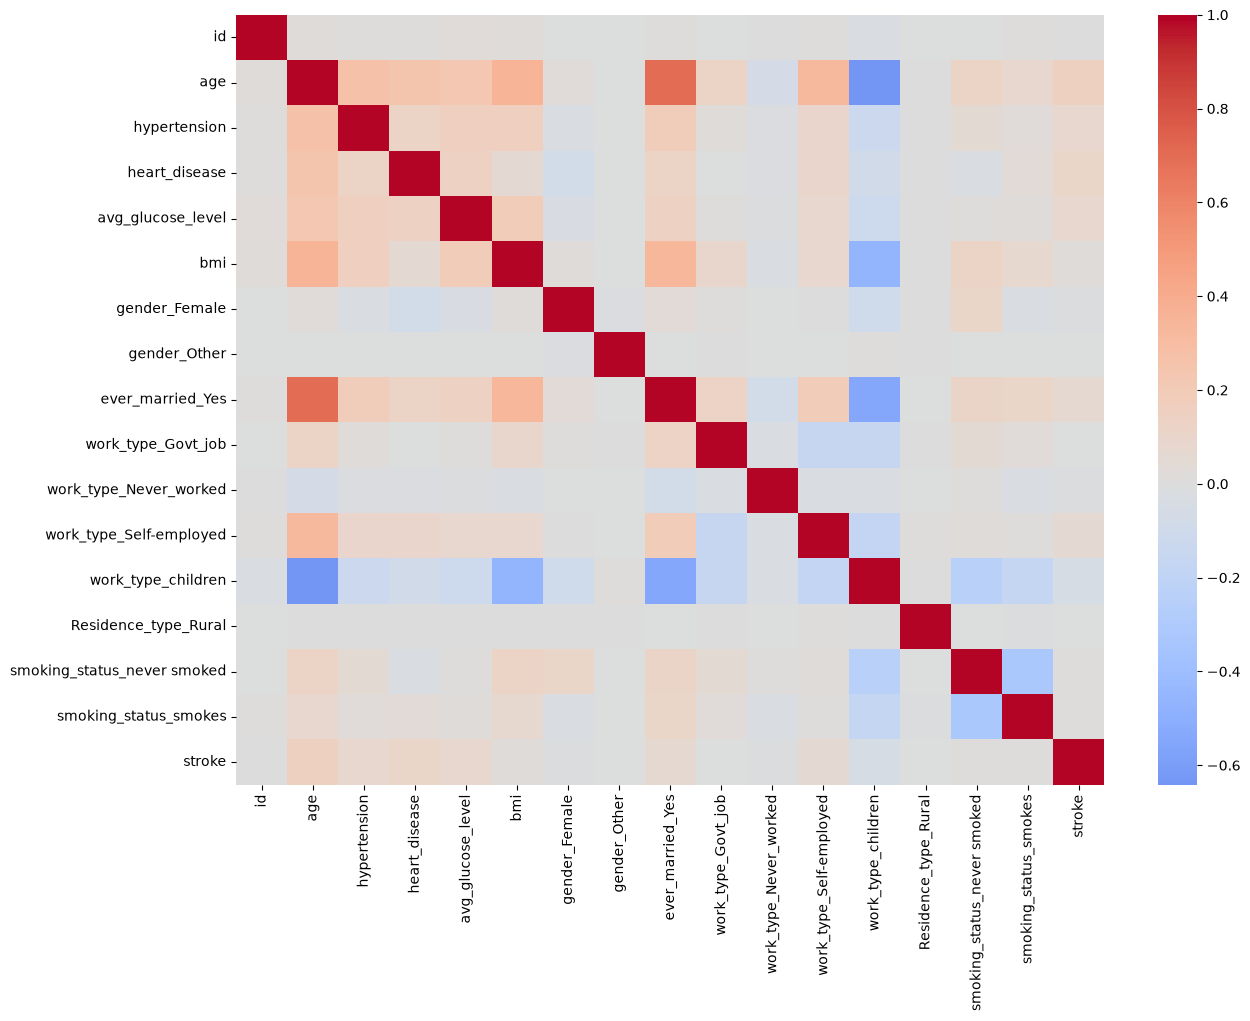

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(train.corr(), cmap="coolwarm", center=0)
plt.show()

In [45]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorische kolommen:", list(categorical_cols))
print("Numerieke kolommen:", list(numerical_cols))



Categorische kolommen: []
Numerieke kolommen: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']


In [46]:
y.value_counts(normalize=True)

stroke
0    0.98459
1    0.01541
Name: proportion, dtype: float64

### 1.4 Relaties tussen onafhankelijke variabelen en afhankelijke variabele

<Axes: xlabel='stroke', ylabel='bmi'>

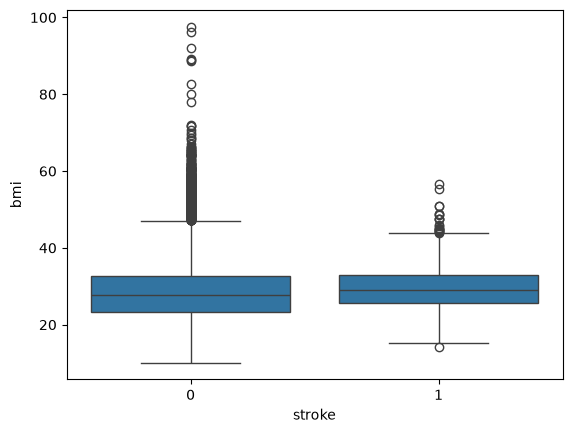

In [47]:
sns.boxplot(data= train, x='stroke', y= 'bmi')

##### De boxplot toont de verdeling van BMI voor personen met en zonder beroerte. De mediane BMI‑waarden liggen dicht bij elkaar en de interkwartielafstanden overlappen volledig. Dit wijst erop dat BMI geen duidelijke verschillen vertoont tussen de stroke‑ en niet‑stroke‑groep. Hoewel er enkele outliers aanwezig zijn, komen deze in beide groepen voor. Op basis van deze visualisatie lijkt BMI geen sterke relatie te hebben met het optreden van een beroerte.

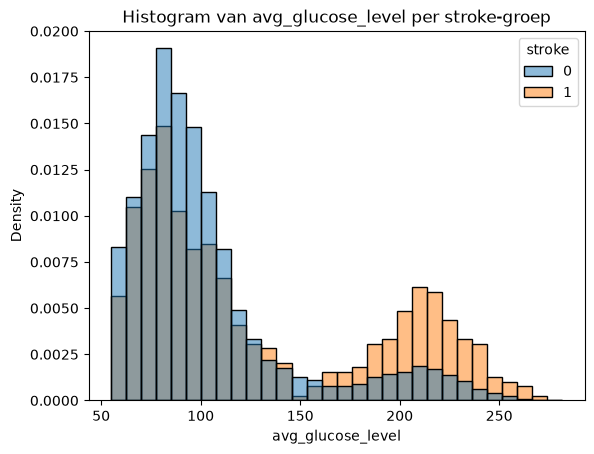

In [48]:
sns.histplot(data=train, x='avg_glucose_level', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("Histogram van avg_glucose_level per stroke-groep")
plt.show()

##### in deze density-histogram is te zien dat de verdelingen van avg_glucose_level voor stroke- en niet-stroke-groepen niet volledig is gescheiden. omdat de dataset sterk geonbalanceerd is, is gebruik gemaakt van densityplot, waarbij elke groep wordt genormaliseerd zodat de vorm van de verdeling zichtbaar blijkt. De niet‑stroke‑groep heeft glucosewaarden tussen 50 en 160, terwijl de stroke‑groep geconcentreerd is rond de waarden 130 - 280. De verdelingen overlappen slechts minimaal, wat wijst op een sterke relatie tussen hogere glucosewaarden en het optreden van een beroerte.

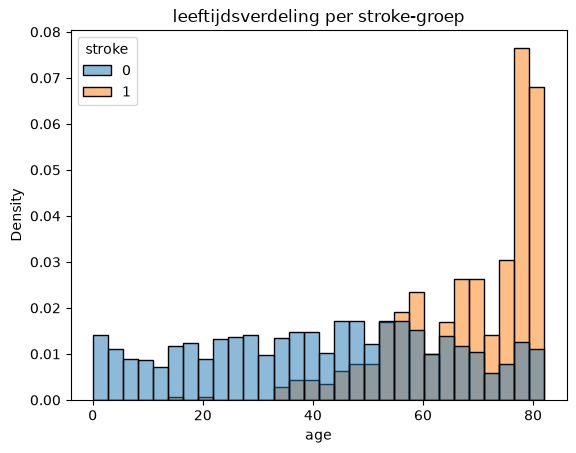

In [49]:
sns.histplot(data=train, x='age', hue='stroke', kde= False, bins= 30, stat= "density", common_norm= False )
plt.title("leeftijdsverdeling per stroke-groep")
plt.show()

##### De densityplot toont een duidelijke relatie tussen leeftijd en het optreden van een beroerte. de verdeling van de stroke-groep is sterk geconcentreerd rond hogere leeftijden (60-80 jaar), terwijl de niet-stroke groep breder verdeeld is over jongere leeftijden (0-50 jaar). Omdat de dataset ongebalanceerd is, is gebruikgemaakt van een densityplot, waardoor de vorm van beide verdelingen zichtbaar blijft. De verdelingen overlappen slechts beperkt, wat aangeeft dat leeftijd een sterke voorspeller is voor het optreden van een beroerte, hoewel er enkele uitzonderingen zijn.

uitleg

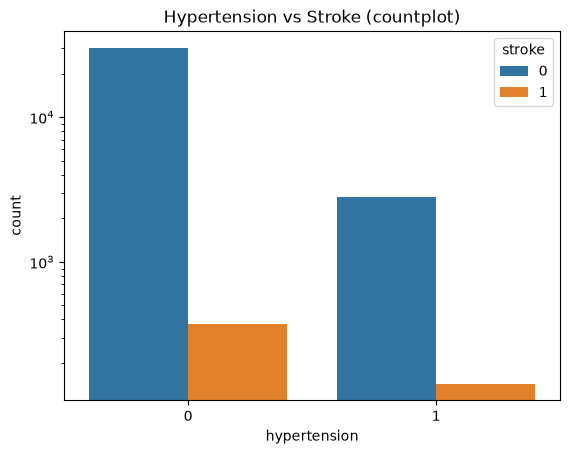

In [50]:
sns.countplot(data=train, x="hypertension", hue="stroke")
plt.title("Hypertension vs Stroke (countplot)")
plt.yscale("log")
plt.show()

##### De countplot toont de relatie tussen hypertension en stroke. Omdat de dataset sterk ongebalanceerd is, is een logaritmische y‑as gebruikt om de kleine stroke‑groep zichtbaar te maken. Uit de visualisatie blijkt dat personen met hypertension relatief vaker een beroerte hebben dan personen zonder hypertension: de oranje balk (stroke = 1) is duidelijk hoger bij hypertension = 1. Dit wijst op een duidelijke relatie tussen hoge bloeddruk en het optreden van een beroerte.

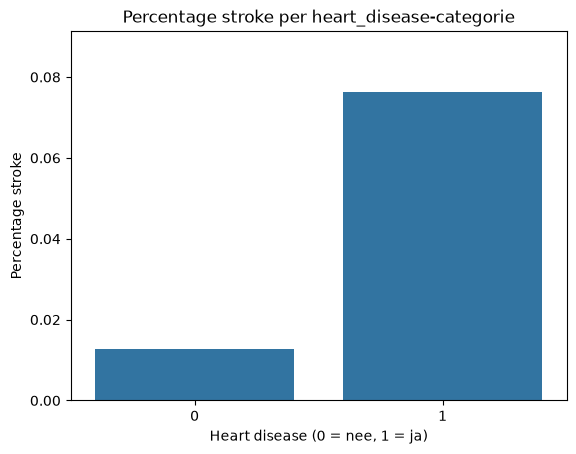

In [51]:
percentages = (
    train.groupby("heart_disease")["stroke"]
    .mean()
    .reset_index()
)

# Plot
sns.barplot(data=percentages, x="heart_disease", y="stroke")
plt.title("Percentage stroke per heart_disease-categorie")
plt.xlabel("Heart disease (0 = nee, 1 = ja)")
plt.ylabel("Percentage stroke")
plt.ylim(0, percentages["stroke"].max() * 1.2)
plt.show()

##### De percentage‑barplot laat zien welk deel van de personen binnen elke heart_disease‑categorie een beroerte heeft gehad. Omdat zowel heart_disease als stroke binaire variabelen zijn, is een percentageplot geschikt om de kans op een beroerte per categorie te vergelijken. Uit de visualisatie blijkt dat het percentage stroke hoger is bij personen met heart_disease dan bij personen zonder heart_disease. Dit wijst op een duidelijke relatie tussen hartziekte en het optreden van een beroerte: mensen met heart_disease hebben relatief vaker een beroerte dan mensen zonder heart_disease

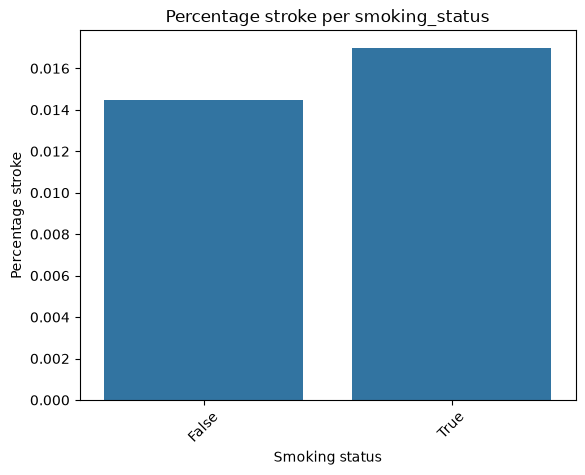

In [ ]:
percent_smoking = (
    train.groupby("smoking_status_never smoked")["stroke"]
    .mean()
    .reset_index()
)

sns.barplot(data=percent_smoking, x="smoking_status_never smoked", y="stroke")
plt.title("Percentage stroke per smoking_status")
plt.xlabel("Smoking status")
plt.ylabel("Percentage stroke")
plt.xticks(rotation=45)
plt.show()

##### “De variabele ‘smoking_status_never smoked’ geeft aan of een persoon nooit heeft gerookt (True) of tot een andere rookcategorie behoort (False). De percentage‑barplot toont dat het percentage beroertes iets hoger is bij personen die nooit hebben gerookt. Dit betekent echter niet dat nooit roken een risicofactor is; het verschil wordt verklaard door leeftijd. De groep ‘never smoked’ bevat waarchijnlijk relatief meer oudere personen, terwijl de groep ‘False’ veel jongere personen bevat (zoals ex‑rokers en onbekende categorieën). Omdat leeftijd een sterke voorspeller is voor stroke, ontstaat dit verschil. De variabele smoking_status lijkt daarom geen sterke directe relatie te hebben met stroke.

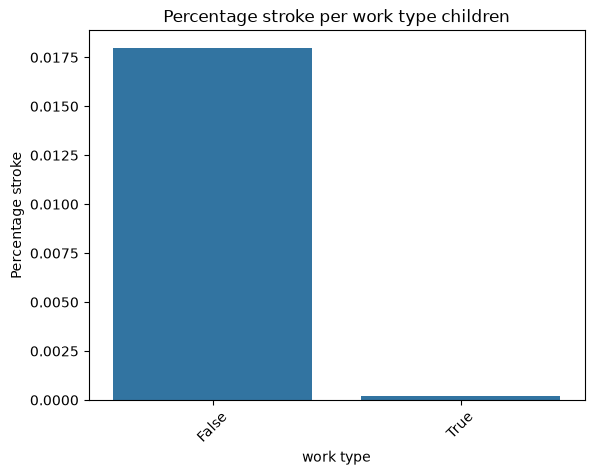

In [57]:
percent_smoking = (
    train.groupby("work_type_children")["stroke"]
    .mean()
    .reset_index()
)

sns.barplot(data=percent_smoking, x="work_type_children", y="stroke")
plt.title("Percentage stroke per work type children")
plt.xlabel("work type")
plt.ylabel("Percentage stroke")
plt.xticks(rotation=45)
plt.show()

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y)